# Window KRR Playground: `us_births/W`

This notebook treats `us_births/W` as its own forecasting problem and uses the
shared window-based kernel ridge regression code in `src/window_krr.py`.

It supports:
- short-term forecasting of `validation \ train` using the `train` split,
- direct test-window forecasting using the `validation` split,
- recursive chunked forecasting from the validation endpoint.

The top parameter cell is meant to be edited freely.

In [1]:
import os
import sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate the KMD_TS repository root from the current working directory.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)
print("GIFT_EVAL:", os.environ["GIFT_EVAL"])

Repo root: /Users/jonghyeonlee/KMD_TS
GIFT_EVAL: /Users/jonghyeonlee/KMD_TS/GiftEval_data


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

from gift_eval.data import Dataset
from src.window_krr import (
    KernelConfig,
    WindowKernelRidgeForecaster,
    build_gap_deltas_from_mask,
    build_regular_deltas,
    make_windowed_forecasting_dataset,
    relative_l2_error,
)

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [24]:
DATASET_NAME = "us_births/W"
TERM = "short"
TO_UNIVARIATE = False

# Pick the series you want to visualize and evaluate.
SERIES_INDEX = 0

# Keep these conservative by default so large datasets stay interactive.
MAX_SERIES = 200
MAX_WINDOWS_PER_SERIES = 20

CONTEXT_LENGTH = 200
SHORT_HORIZON = None         # defaults to dataset.prediction_length
LONG_HORIZON = None          # defaults to dataset.prediction_length
TRAIN_STRIDE = None          # defaults to SHORT_HORIZON
VALIDATION_STRIDE = None     # defaults to LONG_HORIZON

REPRESENTATION = "plain"    # one of: "masked", "interleaved", "plain"
KERNEL_FAMILY = "rbf"        # one of: rbf, matern25, polynomial, laplace, inverse_quadratic, linear
AMPLITUDE = 1.0
LENGTH_SCALE = 10000000.0
DEGREE = 2
GAMMA = None
COEF0 = 1.0
MASK_MODE = "multiply"       # one of: "none", "multiply", "add"
MASK_SIMILARITY = "jaccard"  # one of: "jaccard", "overlap_fraction", "dot"
MASK_WEIGHT = 1.0
REGULARIZATION = 1e-5

# Delta handling for the interleaved representation.
# "regular" means every step has the same delta.
# "since_last_observed" turns missing stretches into increasing deltas.
DELTA_MODE = "regular"       # one of: "regular", "since_last_observed"
DELTA_STEP = 1.0

# Test-time controls
TEST_WINDOW_INDEX = 0
ROLLING_TEST_WINDOW_LIMIT = None     # set to an integer to cap rolling evaluation windows
PLOT_STITCHED_TEST_TAIL = True       # plot the concatenated direct test-tail forecast
RECURSIVE_TOTAL_HORIZON = None       # defaults to dataset.windows * dataset.prediction_length
RECURSIVE_CHUNK_LENGTH = None        # defaults to LONG_HORIZON

# Evaluation scope
EVALUATE_ALL_SERIES = False          # if False, evaluate SERIES_INDEX only
EVAL_SERIES_LIMIT = None             # optional cap when EVALUATE_ALL_SERIES=True
PLOT_FIRST_SERIES_WHEN_AGGREGATING = False

## Kernel Representations

Set `REPRESENTATION` in the parameter cell to:
- `"masked"` for the mask-aware kernel `k((x,m),(x',m'))`
- `"interleaved"` for the observed-only interleaved feature map
  `z=(x_{j_1},Δ_{j_1},...,x_{j_r},Δ_{j_r})`, where `j_1 < ... < j_r` are the observed indices
- `"plain"` for value-only kernels

For interleaved kernels:
- `DELTA_MODE="regular"` uses constant time steps
- `DELTA_MODE="since_last_observed"` increases the delta across missing stretches

Note: internally, interleaved features are stored in padded arrays only so they can
fit in a matrix, but padded coordinates are always masked out of the kernel. They
do not contribute as zero-valued observations.

In [25]:
dataset = Dataset(
    name=DATASET_NAME,
    term=TERM,
    to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)

print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : us_births/W
frequency          : W-TUE
prediction_length  : 8
test windows/series: 14
n_raw_series       : 1
target_dim         : 1


In [26]:
def _nth_item(data_it, index: int):
    for i, item in enumerate(data_it):
        if i == index:
            return item
    raise IndexError(f"Index {{index}} is out of range.")


def _series_from_entry(entry) -> np.ndarray:
    return np.asarray(entry["target"], dtype=float).reshape(-1)


def _get_train_entry(series_index: int):
    return _nth_item(dataset.training_dataset, series_index)


def _get_validation_entry(series_index: int):
    return _nth_item(dataset.validation_dataset, series_index)


def _get_test_pair(series_index: int, window_index: int):
    if window_index < 0 or window_index >= dataset.windows:
        raise IndexError(
            f"window_index={{window_index}} is out of range for dataset.windows={{dataset.windows}}."
        )
    flat_index = series_index * dataset.windows + window_index
    test_context = _nth_item(dataset.test_data.input, flat_index)
    test_label = _nth_item(dataset.test_data.label, flat_index)
    return test_context, test_label


def _get_all_test_pairs_for_series(series_index: int, *, limit: int | None = None):
    n_windows = dataset.windows if limit is None else min(int(limit), dataset.windows)
    pairs = []
    for window_index in range(n_windows):
        pairs.append(_get_test_pair(series_index, window_index))
    return pairs


def _get_test_tail(series_index: int, *, limit: int | None = None) -> np.ndarray:
    label_blocks = [
        _series_from_entry(label_entry)
        for _, label_entry in _get_all_test_pairs_for_series(series_index, limit=limit)
    ]
    if not label_blocks:
        return np.empty((0,), dtype=float)
    return np.concatenate(label_blocks)


def _get_validation_plus_test_series(series_index: int, *, limit: int | None = None) -> np.ndarray:
    val = _series_from_entry(_get_validation_entry(series_index))
    test_tail = _get_test_tail(series_index, limit=limit)
    if test_tail.size == 0:
        return val.copy()
    return np.concatenate([val, test_tail])


def _validation_minus_train(series_index: int) -> np.ndarray:
    train = _series_from_entry(_get_train_entry(series_index))
    val = _series_from_entry(_get_validation_entry(series_index))
    return val[len(train):]


def _kernel_config() -> KernelConfig:
    return KernelConfig(
        family=KERNEL_FAMILY,
        amplitude=AMPLITUDE,
        length_scale=LENGTH_SCALE,
        degree=DEGREE,
        gamma=GAMMA,
        coef0=COEF0,
        mask_mode=MASK_MODE,
        mask_similarity=MASK_SIMILARITY,
        mask_weight=MASK_WEIGHT,
    )


def _build_deltas_from_values(values: np.ndarray) -> np.ndarray:
    observed_mask = np.isfinite(values)
    if DELTA_MODE == "regular":
        return build_regular_deltas(len(values), step=DELTA_STEP)
    if DELTA_MODE == "since_last_observed":
        return build_gap_deltas_from_mask(observed_mask, step=DELTA_STEP)
    raise ValueError(
        f"Unsupported DELTA_MODE={{DELTA_MODE}}. "
        "Supported modes are 'regular' and 'since_last_observed'."
    )


def _build_window_bank_from_split(
    split_name: str,
    *,
    context_length: int,
    horizon_length: int,
    stride: int | None,
    max_series: int | None,
    max_windows_per_series: int | None,
):
    if split_name not in {"train", "validation"}:
        raise ValueError("split_name must be either 'train' or 'validation'.")
    if context_length <= 0:
        raise ValueError("context_length must be positive.")
    if horizon_length <= 0:
        raise ValueError("horizon_length must be positive.")

    entry_iter = dataset.training_dataset if split_name == "train" else dataset.validation_dataset
    stride = horizon_length if stride is None else int(stride)
    if stride <= 0:
        raise ValueError("stride must be positive.")

    contexts = []
    targets = []
    context_masks = []
    target_masks = []
    context_deltas = []
    target_deltas = []
    used_series = 0
    skipped = []

    for series_index, entry in enumerate(entry_iter):
        if max_series is not None and series_index >= max_series:
            break
        values = _series_from_entry(entry)
        observed_mask = np.isfinite(values)
        deltas = _build_deltas_from_values(values)
        try:
            windowed = make_windowed_forecasting_dataset(
                values,
                context_length=context_length,
                horizon_length=horizon_length,
                observed_mask=observed_mask,
                deltas=deltas,
                stride=stride,
                max_windows=max_windows_per_series,
                include_last=True,
                drop_all_missing_targets=True,
            )
        except ValueError as exc:
            skipped.append((series_index, str(exc)))
            continue

        contexts.append(windowed.contexts)
        targets.append(windowed.targets)
        context_masks.append(windowed.context_masks)
        target_masks.append(windowed.target_masks)
        context_deltas.append(windowed.context_deltas)
        target_deltas.append(windowed.target_deltas)
        used_series += 1

    if not contexts:
        raise ValueError(
            f"No valid windows could be built from split '{{split_name}}'. "
            "Try reducing CONTEXT_LENGTH, LONG_HORIZON/SHORT_HORIZON, or MAX_WINDOWS_PER_SERIES."
        )

    return {
        "contexts": np.vstack(contexts),
        "targets": np.vstack(targets),
        "context_masks": np.vstack(context_masks),
        "target_masks": np.vstack(target_masks),
        "context_deltas": np.vstack(context_deltas),
        "target_deltas": np.vstack(target_deltas),
        "used_series": used_series,
        "n_windows": sum(arr.shape[0] for arr in contexts),
        "skipped": skipped,
    }


def _make_forecaster():
    return WindowKernelRidgeForecaster(
        kernel_config=_kernel_config(),
        representation=REPRESENTATION,
        regularization=REGULARIZATION,
    )


def _plot_forecast(y_true, y_pred, *, title: str, mask=None):
    true_arr = np.asarray(y_true, dtype=float).reshape(-1)
    pred_arr = np.asarray(y_pred, dtype=float).reshape(-1)
    if mask is None:
        obs_mask = np.isfinite(true_arr)
    else:
        obs_mask = np.asarray(mask, dtype=bool).reshape(-1) & np.isfinite(true_arr)

    t = np.arange(1, true_arr.shape[0] + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, true_arr, label="true", linewidth=2)
    plt.plot(t, pred_arr, label="predicted", linewidth=2)
    if not obs_mask.all():
        plt.scatter(t[~obs_mask], np.zeros((~obs_mask).sum()), marker="x", label="missing target")
    plt.title(title)
    plt.xlabel("time index within forecast horizon")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def _evaluation_series_indices():
    if not EVALUATE_ALL_SERIES:
        return [SERIES_INDEX]
    limit = len(dataset.hf_dataset) if EVAL_SERIES_LIMIT is None else min(int(EVAL_SERIES_LIMIT), len(dataset.hf_dataset))
    if limit <= 0:
        raise ValueError("EVAL_SERIES_LIMIT must be positive when provided.")
    return list(range(limit))


def _print_error_summary(name: str, errors: list[float], skipped: list[tuple[int, str]]):
    if not errors:
        raise ValueError(f"No valid evaluation series were available for {name}.")
    arr = np.asarray(errors, dtype=float)
    print(f"{name} evaluated series:", len(errors))
    print(f"{name} skipped series  :", len(skipped))
    print(f"{name} mean relative L2:", float(np.mean(arr)))
    print(f"{name} median relative L2:", float(np.median(arr)))
    print(f"{name} min relative L2 :", float(np.min(arr)))
    print(f"{name} max relative L2 :", float(np.max(arr)))

Selected series index: 0
train length         : 923
validation length    : 931
validation\train len : 8


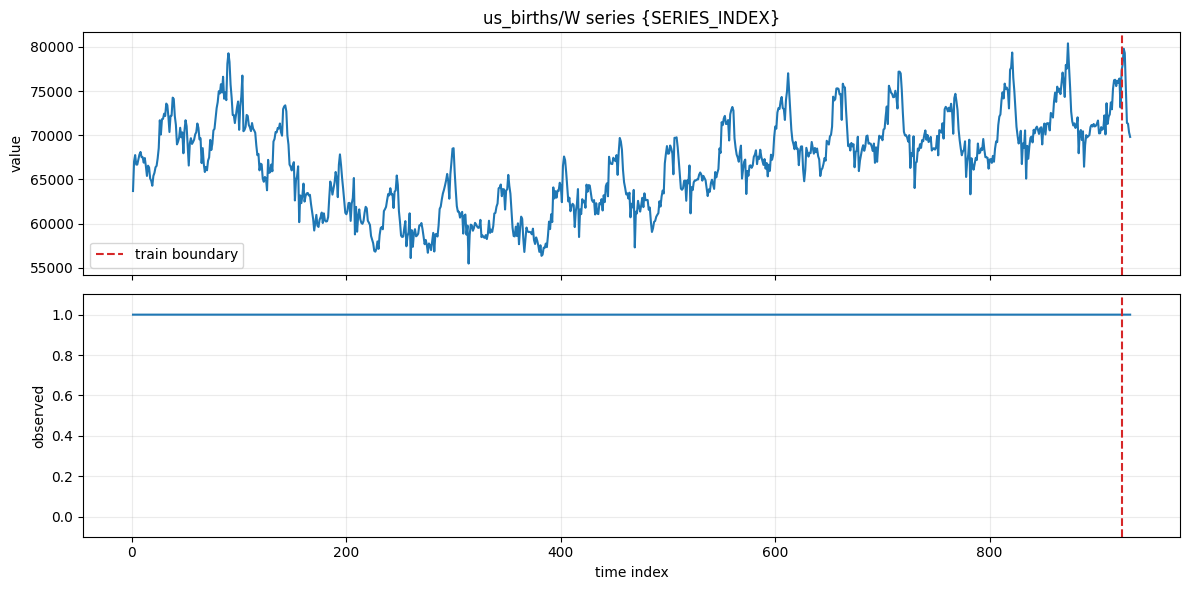

In [27]:
train_entry = _get_train_entry(SERIES_INDEX)
val_entry = _get_validation_entry(SERIES_INDEX)

train_series = _series_from_entry(train_entry)
val_series = _series_from_entry(val_entry)
val_extra = val_series[len(train_series):]
val_mask = np.isfinite(val_series).astype(int)

print("Selected series index:", SERIES_INDEX)
print("train length         :", len(train_series))
print("validation length    :", len(val_series))
print("validation\\train len :", len(val_extra))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(np.arange(1, len(val_series) + 1), val_series, linewidth=1.5)
axes[0].axvline(len(train_series), color="tab:red", linestyle="--", label="train boundary")
axes[0].set_title(f"{DATASET_NAME} series {{SERIES_INDEX}}")
axes[0].set_ylabel("value")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].step(np.arange(1, len(val_mask) + 1), val_mask, where="post")
axes[1].axvline(len(train_series), color="tab:red", linestyle="--")
axes[1].set_ylabel("observed")
axes[1].set_xlabel("time index")
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Short-Term Forecast: `train -> validation \\ train`

Short-term bank windows: 20
Short-term bank series : 1
Short-term skipped     : 0


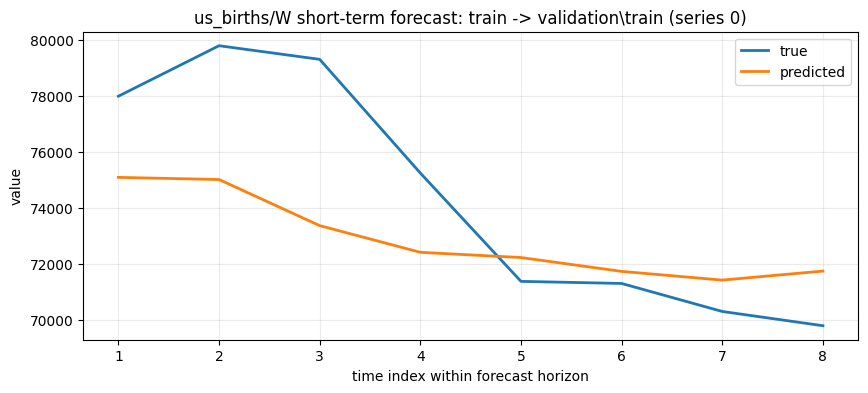

Short-term relative L2: 0.042504902749959


In [28]:
short_horizon = dataset.prediction_length if SHORT_HORIZON is None else int(SHORT_HORIZON)
if short_horizon <= 0:
    raise ValueError("SHORT_HORIZON must be positive.")

val_extra = _validation_minus_train(SERIES_INDEX)
if not EVALUATE_ALL_SERIES:
    if short_horizon > len(val_extra):
        raise ValueError(
            f"SHORT_HORIZON={{short_horizon}} exceeds len(validation\\train)={{len(val_extra)}}. "
            "Reduce SHORT_HORIZON or use a different development target."
        )

    if CONTEXT_LENGTH > len(train_series):
        raise ValueError(
            f"CONTEXT_LENGTH={{CONTEXT_LENGTH}} exceeds training length {{len(train_series)}} "
            f"for series {{SERIES_INDEX}}."
        )

short_bank = _build_window_bank_from_split(
    "train",
    context_length=CONTEXT_LENGTH,
    horizon_length=short_horizon,
    stride=TRAIN_STRIDE,
    max_series=MAX_SERIES,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
)
print("Short-term bank windows:", short_bank["n_windows"])
print("Short-term bank series :", short_bank["used_series"])
print("Short-term skipped     :", len(short_bank["skipped"]))

short_model = _make_forecaster()
short_model.fit(
    short_bank["contexts"],
    short_bank["targets"],
    context_masks=short_bank["context_masks"],
    target_masks=short_bank["target_masks"],
    context_deltas=short_bank["context_deltas"],
)

short_errors = []
short_skipped = []
plotted = False
for eval_series_index in _evaluation_series_indices():
    eval_train = _series_from_entry(_get_train_entry(eval_series_index))
    eval_val_extra = _validation_minus_train(eval_series_index)
    if CONTEXT_LENGTH > len(eval_train):
        short_skipped.append((eval_series_index, "context longer than train prefix"))
        continue
    if short_horizon > len(eval_val_extra):
        short_skipped.append((eval_series_index, "short horizon longer than validation\\train"))
        continue

    short_query = eval_train[-CONTEXT_LENGTH:]
    short_pred = short_model.forecast(
        short_query,
        strategy="direct",
        total_horizon=short_horizon,
        query_masks=np.isfinite(short_query),
        query_deltas=_build_deltas_from_values(short_query),
    ).reshape(-1)

    short_true = eval_val_extra[:short_horizon]
    short_mask = np.isfinite(short_true)
    short_rel_l2 = relative_l2_error(short_true, short_pred, mask=short_mask)
    short_errors.append(short_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
    )
    if should_plot:
        _plot_forecast(
            short_true,
            short_pred,
            title=f"{DATASET_NAME} short-term forecast: train -> validation\\train (series {eval_series_index})",
            mask=short_mask,
        )
        plotted = True

if EVALUATE_ALL_SERIES:
    _print_error_summary("Short-term", short_errors, short_skipped)
else:
    print("Short-term relative L2:", short_errors[0])

## Long-Term Forecast: `validation -> test`

Long-term bank windows: 20
Long-term bank series : 1
Long-term skipped     : 0


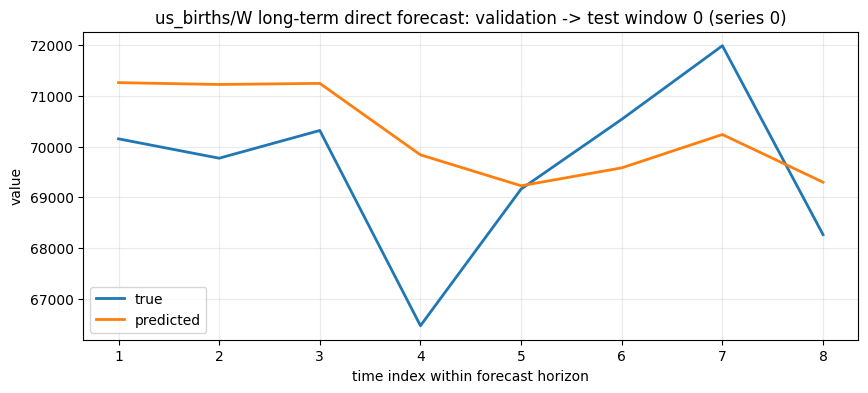

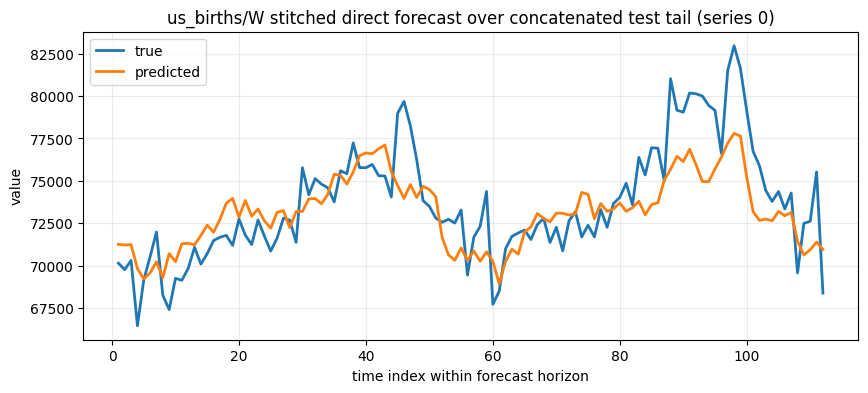

Selected test window index: 0
Long-term relative L2     : 0.023060427775506803
Stitched direct tail L2   : 0.029761755673384033
Rolling test windows evaluated: 14
Rolling mean relative L2      : 0.027117079912123955


In [29]:
long_horizon = dataset.prediction_length if LONG_HORIZON is None else int(LONG_HORIZON)
if long_horizon <= 0:
    raise ValueError("LONG_HORIZON must be positive.")
if not EVALUATE_ALL_SERIES and CONTEXT_LENGTH > len(val_series):
    raise ValueError(
        f"CONTEXT_LENGTH={{CONTEXT_LENGTH}} exceeds validation length {{len(val_series)}} "
        f"for series {{SERIES_INDEX}}."
    )

validation_bank = _build_window_bank_from_split(
    "validation",
    context_length=CONTEXT_LENGTH,
    horizon_length=long_horizon,
    stride=VALIDATION_STRIDE,
    max_series=MAX_SERIES,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
)
print("Long-term bank windows:", validation_bank["n_windows"])
print("Long-term bank series :", validation_bank["used_series"])
print("Long-term skipped     :", len(validation_bank["skipped"]))

long_model = _make_forecaster()
long_model.fit(
    validation_bank["contexts"],
    validation_bank["targets"],
    context_masks=validation_bank["context_masks"],
    target_masks=validation_bank["target_masks"],
    context_deltas=validation_bank["context_deltas"],
)

direct_errors = []
direct_skipped = []
stitched_errors = []
stitched_skipped = []
rolling_means = []
rolling_skipped = []
block_plotted = False
stitched_plotted = False

for eval_series_index in _evaluation_series_indices():
    test_context_entry, test_label_entry = _get_test_pair(eval_series_index, TEST_WINDOW_INDEX)
    test_context = _series_from_entry(test_context_entry)
    test_label = _series_from_entry(test_label_entry)
    if CONTEXT_LENGTH > len(test_context):
        direct_skipped.append((eval_series_index, "context longer than selected test context"))
        continue
    if long_horizon > len(test_label):
        direct_skipped.append((eval_series_index, "long horizon longer than selected test label"))
        continue

    long_query = test_context[-CONTEXT_LENGTH:]
    long_pred = long_model.forecast(
        long_query,
        strategy="direct",
        total_horizon=long_horizon,
        query_masks=np.isfinite(long_query),
        query_deltas=_build_deltas_from_values(long_query),
    ).reshape(-1)

    long_true = test_label[:long_horizon]
    long_mask = np.isfinite(long_true)
    long_rel_l2 = relative_l2_error(long_true, long_pred, mask=long_mask)
    direct_errors.append(long_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not block_plotted
    )
    if should_plot:
        _plot_forecast(
            long_true,
            long_pred,
            title=f"{DATASET_NAME} long-term direct forecast: validation -> test window {TEST_WINDOW_INDEX} (series {eval_series_index})",
            mask=long_mask,
        )
        block_plotted = True

    all_pairs = _get_all_test_pairs_for_series(eval_series_index, limit=ROLLING_TEST_WINDOW_LIMIT)
    per_series_rolling = []
    stitched_truth_blocks = []
    stitched_pred_blocks = []
    for pair_index, (ctx_entry, lbl_entry) in enumerate(all_pairs):
        ctx = _series_from_entry(ctx_entry)
        lbl = _series_from_entry(lbl_entry)
        if CONTEXT_LENGTH > len(ctx) or long_horizon > len(lbl):
            continue
        pred = long_model.forecast(
            ctx[-CONTEXT_LENGTH:],
            strategy="direct",
            total_horizon=long_horizon,
            query_masks=np.isfinite(ctx[-CONTEXT_LENGTH:]),
            query_deltas=_build_deltas_from_values(ctx[-CONTEXT_LENGTH:]),
        ).reshape(-1)
        truth = lbl[:long_horizon]
        per_series_rolling.append(relative_l2_error(truth, pred, mask=np.isfinite(truth)))
        stitched_truth_blocks.append(truth)
        stitched_pred_blocks.append(pred)

    if per_series_rolling:
        rolling_means.append(float(np.mean(per_series_rolling)))
    else:
        rolling_skipped.append((eval_series_index, "no valid rolling test windows"))

    if stitched_truth_blocks:
        stitched_true = np.concatenate(stitched_truth_blocks)
        stitched_pred = np.concatenate(stitched_pred_blocks)
        stitched_mask = np.isfinite(stitched_true)
        stitched_errors.append(relative_l2_error(stitched_true, stitched_pred, mask=stitched_mask))

        should_plot_stitched = PLOT_STITCHED_TEST_TAIL and (
            (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
                EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not stitched_plotted
            )
        )
        if should_plot_stitched:
            _plot_forecast(
                stitched_true,
                stitched_pred,
                title=f"{DATASET_NAME} stitched direct forecast over concatenated test tail (series {eval_series_index})",
                mask=stitched_mask,
            )
            stitched_plotted = True
    else:
        stitched_skipped.append((eval_series_index, "no valid stitched test-tail blocks"))

print("Selected test window index:", TEST_WINDOW_INDEX)
if EVALUATE_ALL_SERIES:
    _print_error_summary("Long-term direct", direct_errors, direct_skipped)
    if stitched_errors:
        _print_error_summary("Long-term stitched-tail direct", stitched_errors, stitched_skipped)
    else:
        print("No stitched direct test-tail forecasts could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
    if rolling_means:
        _print_error_summary("Long-term rolling-mean", rolling_means, rolling_skipped)
    else:
        print("No rolling test windows could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
else:
    print("Long-term relative L2     :", direct_errors[0])
    if stitched_errors:
        print("Stitched direct tail L2   :", stitched_errors[0])
    else:
        print("No stitched direct test-tail forecast could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")
    if rolling_means:
        print("Rolling test windows evaluated:", len(_get_all_test_pairs_for_series(SERIES_INDEX, limit=ROLLING_TEST_WINDOW_LIMIT)))
        print("Rolling mean relative L2      :", rolling_means[0])
    else:
        print("No rolling test windows could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")

## Recursive Chunked Forecast from the Validation Endpoint

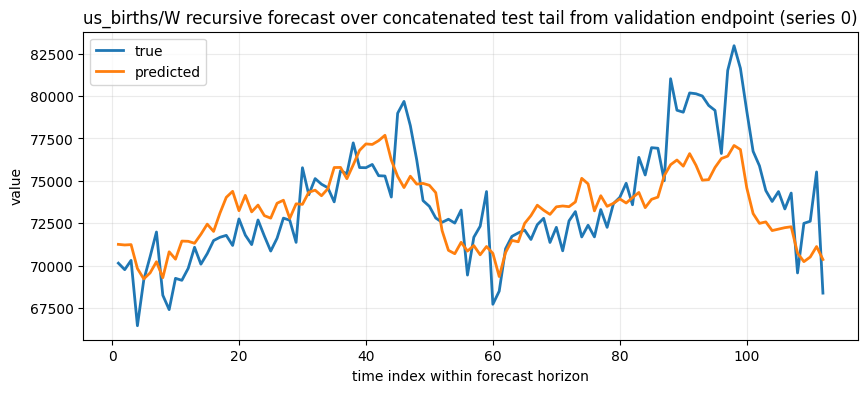

Recursive chunk length: 8
Recursive relative L2  : 0.031054138552214547


In [30]:
recursive_chunk_length = long_horizon if RECURSIVE_CHUNK_LENGTH is None else int(RECURSIVE_CHUNK_LENGTH)
if recursive_chunk_length <= 0:
    raise ValueError("RECURSIVE_CHUNK_LENGTH must be positive.")
if recursive_chunk_length > long_horizon:
    raise ValueError(
        f"RECURSIVE_CHUNK_LENGTH={{recursive_chunk_length}} exceeds LONG_HORIZON={{long_horizon}}."
    )

recursive_errors = []
recursive_skipped = []
plotted = False

for eval_series_index in _evaluation_series_indices():
    eval_val_series = _series_from_entry(_get_validation_entry(eval_series_index))
    if CONTEXT_LENGTH > len(eval_val_series):
        recursive_skipped.append((eval_series_index, "context longer than validation prefix"))
        continue

    recursive_truth = _get_test_tail(eval_series_index)
    recursive_mask = np.isfinite(recursive_truth)

    recursive_total_horizon = len(recursive_truth) if RECURSIVE_TOTAL_HORIZON is None else int(RECURSIVE_TOTAL_HORIZON)
    if recursive_total_horizon <= 0:
        raise ValueError("RECURSIVE_TOTAL_HORIZON must be positive.")
    recursive_total_horizon = min(recursive_total_horizon, len(recursive_truth))

    recursive_query = eval_val_series[-CONTEXT_LENGTH:]
    recursive_pred = long_model.forecast(
        recursive_query,
        strategy="chunked",
        total_horizon=recursive_total_horizon,
        chunk_length=recursive_chunk_length,
        query_masks=np.isfinite(recursive_query),
        query_deltas=_build_deltas_from_values(recursive_query),
        future_deltas=np.full((1, recursive_total_horizon), DELTA_STEP, dtype=float),
    ).reshape(-1)

    recursive_true = recursive_truth[:recursive_total_horizon]
    recursive_true_mask = recursive_mask[:recursive_total_horizon]
    recursive_rel_l2 = relative_l2_error(recursive_true, recursive_pred, mask=recursive_true_mask)
    recursive_errors.append(recursive_rel_l2)

    should_plot = (not EVALUATE_ALL_SERIES and eval_series_index == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and PLOT_FIRST_SERIES_WHEN_AGGREGATING and not plotted
    )
    if should_plot:
        _plot_forecast(
            recursive_true,
            recursive_pred,
            title=f"{DATASET_NAME} recursive forecast over concatenated test tail from validation endpoint (series {eval_series_index})",
            mask=recursive_true_mask,
        )
        plotted = True

print("Recursive chunk length:", recursive_chunk_length)
if EVALUATE_ALL_SERIES:
    _print_error_summary("Recursive", recursive_errors, recursive_skipped)
else:
    print("Recursive relative L2  :", recursive_errors[0])